# Step 6 — Evaluasi Sistem Temu Kembali Informasi

**Tujuan praktikum**
1. Mahasiswa memahami koleksi uji: dokumen, query, dan *relevance judgment* (qrels).
2. Mahasiswa mampu menghitung precision, recall, F1, P@k, *Average Precision* (AP), MAP, dan nDCG.
3. Mahasiswa mampu membandingkan kinerja model Boolean, TF-IDF, dan BM25 secara kuantitatif.

**Koleksi uji**: 8 query di `../data/queries.csv` dan penilaian relevansi di `../data/qrels.csv` dengan skala 2 = sangat relevan, 1 = relevan sebagian, dokumen yang tidak tercantum = tidak relevan (0).

In [2]:
# Jalankan sekali jika pustaka belum terpasang:
# !pip install pandas numpy matplotlib Sastrawi
import pandas as pd
pd.set_option("display.max_colwidth", 120)

In [3]:
import math
import matplotlib.pyplot as plt
from stki_utils import (corpus_texts, preprocess, build_inverted_index, boolean_search,
                        TfidfModel, BM25Model, load_queries, load_qrels)

docs = {d: preprocess(t) for d, t in corpus_texts().items()}
queries = load_queries()
qrels = load_qrels()
pd.DataFrame([(q, t, qrels[q]) for q, t in queries.items()], columns=["query_id", "query", "relevansi"])

,query_id,query,relevansi
0,Q1,pencegahan penyakit demam berdarah,"{'D01': 2, 'D05': 1}"
1,Q2,teknologi pertanian modern,"{'D10': 2, 'D09': 2, 'D07': 1, 'D08': 1}"
2,Q3,gizi anak balita,"{'D02': 2, 'D30': 2, 'D05': 1}"
3,Q4,mesin pencari dan indeks dokumen,"{'D13': 2, 'D29': 2, 'D17': 1}"
4,Q5,pemasaran digital UMKM,"{'D19': 2, 'D21': 1, 'D22': 1}"
5,Q6,keamanan data pribadi di internet,"{'D15': 2, 'D27': 1, 'D06': 1}"
6,Q7,harga hasil panen petani,"{'D12': 2, 'D07': 1, 'D23': 1, 'D20': 1}"
7,Q8,pembelajaran daring mahasiswa,"{'D25': 2, 'D28': 1, 'D26': 1}"
8,Q9,olahraga mencegah penyakit jantung dan diabetes,"{'D03': 2, 'D04': 2}"
9,Q10,kecerdasan buatan dan pembelajaran mesin,"{'D14': 2, 'D17': 1, 'D18': 1}"


## Langkah 1 — Precision, recall, dan F1 untuk hasil tak berperingkat
$$P = \frac{|\text{relevan} \cap \text{ditemukan}|}{|\text{ditemukan}|} \qquad R = \frac{|\text{relevan} \cap \text{ditemukan}|}{|\text{relevan}|} \qquad F_1 = \frac{2PR}{P+R}$$

In [4]:
def prf(ditemukan, relevan):
    tp = len(set(ditemukan) & set(relevan))
    p = tp / len(ditemukan) if ditemukan else 0.0
    r = tp / len(relevan) if relevan else 0.0
    f1 = 2 * p * r / (p + r) if p + r else 0.0
    return p, r, f1

index = build_inverted_index(docs)
baris = []
for q, teks in queries.items():
    terms = preprocess(teks)
    for op in ["AND", "OR"]:
        hasil = boolean_search(f" {op} ".join(terms), index, list(docs))
        p, r, f1 = prf(hasil, qrels[q])
        baris.append({"query_id": q, "operator": op, "ditemukan": len(hasil), "P": p, "R": r, "F1": f1})
bool_df = pd.DataFrame(baris)
bool_df.groupby("operator")[["ditemukan", "P", "R", "F1"]].mean().round(4)

,ditemukan,P,R,F1
operator,,,,
AND,0.4167,0.4167,0.1389,0.2083
OR,6.6667,0.4517,0.9167,0.5722


Boolean AND cenderung *precision* tinggi tetapi *recall* rendah (banyak query kosong), sedangkan OR sebaliknya. Inilah *trade-off* precision–recall.

## Langkah 2 — Metrik untuk hasil berperingkat
Kita ambil satu query sebagai contoh perhitungan langkah demi langkah.

In [5]:
bm25 = BM25Model(docs)
q = "Q2"
ranking = [d for d, _ in bm25.search(preprocess(queries[q]), k=10)]
relevan = qrels[q]

langkah, hits = [], 0
for i, d in enumerate(ranking, start=1):
    rel = d in relevan
    hits += rel
    langkah.append({"rank": i, "doc_id": d, "relevan": relevan.get(d, 0),
                    "P@i": hits / i, "R@i": hits / len(relevan), "P@i (jika relevan)": hits / i if rel else None})
tabel = pd.DataFrame(langkah).set_index("rank")
print("Query:", queries[q], "| dokumen relevan:", relevan)
tabel.round(4)

Query: teknologi pertanian modern | dokumen relevan: {'D10': 2, 'D09': 2, 'D07': 1, 'D08': 1}


,doc_id,relevan,P@i,R@i,P@i (jika relevan)
rank,,,,,
1,D10,2,1.0000,0.25,1.0000
2,D12,0,0.5000,0.25,NaN
3,D06,0,0.3333,0.25,NaN
4,D27,0,0.2500,0.25,NaN
5,D08,1,0.4000,0.50,0.4000
6,D09,2,0.5000,0.75,0.5000
7,D07,1,0.5714,1.00,0.5714
8,D23,0,0.5000,1.00,NaN
9,D11,0,0.4444,1.00,NaN


**Average Precision (AP)** adalah rata-rata nilai P@i pada posisi dokumen relevan, dibagi jumlah seluruh dokumen relevan (dokumen relevan yang tidak ditemukan menyumbang 0). **MAP** adalah rata-rata AP seluruh query.

In [6]:
ap = tabel["P@i (jika relevan)"].sum() / len(relevan)
nilai = [round(x, 4) for x in tabel["P@i (jika relevan)"].dropna()]
print(f"AP({q}) = sum({nilai}) / {len(relevan)} = {ap:.4f}")

AP(Q2) = sum([1.0, 0.4, 0.5, 0.5714]) / 4 = 0.6179


**nDCG@k** memperhitungkan relevansi bertingkat dan posisi:
$$DCG@k = \sum_{i=1}^{k} \frac{rel_i}{\log_2(i+1)} \qquad nDCG@k = \frac{DCG@k}{IDCG@k}$$
IDCG adalah DCG dari urutan ideal (semua dokumen paling relevan di atas).

In [7]:
k = 5
gains = [relevan.get(d, 0) for d in ranking[:k]]
ideal = sorted(relevan.values(), reverse=True)[:k]
dcg = sum(g / math.log2(i + 1) for i, g in enumerate(gains, start=1))
idcg = sum(g / math.log2(i + 1) for i, g in enumerate(ideal, start=1))
print("gain hasil :", gains, f"-> DCG@{k}  = {dcg:.4f}")
print("gain ideal :", ideal, f"-> IDCG@{k} = {idcg:.4f}")
print(f"nDCG@{k} = {dcg / idcg:.4f}")

gain hasil : [2, 0, 0, 0, 1] -> DCG@5  = 2.3869
gain ideal : [2, 2, 1, 1] -> IDCG@5 = 4.1925
nDCG@5 = 0.5693


## Langkah 3 — Evaluasi seluruh query
Fungsi `stki_utils.evaluate` menghitung P@k, R@k, F1@k, AP, dan nDCG@k untuk setiap query, ditambah baris rata-rata (rata-rata kolom AP = **MAP**).

In [8]:
from stki_utils import evaluate, average_precision, ndcg_at_k

tfidf = TfidfModel(docs)
run_tfidf = {q: [d for d, _ in tfidf.search(preprocess(t), k=10)] for q, t in queries.items()}
run_bm25 = {q: [d for d, _ in bm25.search(preprocess(t), k=10)] for q, t in queries.items()}

# cek konsistensi dengan perhitungan manual di atas
assert abs(average_precision(run_bm25["Q2"], set(qrels["Q2"])) - ap) < 1e-9
assert abs(ndcg_at_k(run_bm25["Q2"], qrels["Q2"], 5) - dcg / idcg) < 1e-9

evaluate(run_bm25, qrels, k=5)

,P@5,R@5,F1@5,AP,nDCG@5
query_id,,,,,
Q1,0.4000,1.0000,0.5714,0.7500,0.9239
Q2,0.4000,0.5000,0.4444,0.6179,0.5693
Q3,0.4000,0.6667,0.5000,0.6667,0.8671
Q4,0.4000,0.6667,0.5000,0.5556,0.7975
Q5,0.6000,1.0000,0.7500,1.0000,1.0000
Q6,0.4000,0.6667,0.5000,0.8095,0.8403
Q7,0.8000,1.0000,0.8889,1.0000,1.0000
Q8,0.6000,1.0000,0.7500,0.8056,0.9360
Q9,0.4000,1.0000,0.5714,1.0000,1.0000


## Langkah 4 — Membandingkan model

In [9]:
# Boolean OR diurutkan berdasarkan doc_id (tidak ada skor) sebagai baseline tanpa peringkat
run_bool = {q: boolean_search(" OR ".join(preprocess(t)), index, list(docs))[:10] for q, t in queries.items()}

ringkasan = pd.DataFrame({
    "Boolean OR": evaluate(run_bool, qrels, k=5).loc["Rata-rata"],
    "TF-IDF (VSM)": evaluate(run_tfidf, qrels, k=5).loc["Rata-rata"],
    "BM25": evaluate(run_bm25, qrels, k=5).loc["Rata-rata"],
}).T.rename(columns={"AP": "MAP"})
ringkasan

,P@5,R@5,F1@5,MAP,nDCG@5
Boolean OR,0.4500,0.7986,0.5688,0.5776,0.6516
TF-IDF (VSM),0.4667,0.8194,0.5873,0.7927,0.8781
BM25,0.4667,0.8194,0.5873,0.8018,0.8811


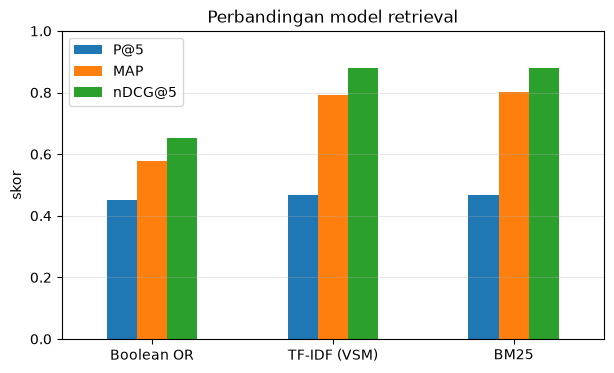

In [10]:
ax = ringkasan[["P@5", "MAP", "nDCG@5"]].plot.bar(figsize=(7, 4), rot=0)
ax.set_ylim(0, 1); ax.set_ylabel("skor"); ax.set_title("Perbandingan model retrieval")
ax.grid(axis="y", alpha=.3); plt.show()

## Langkah 5 — Kurva precision–recall terinterpolasi 11 titik

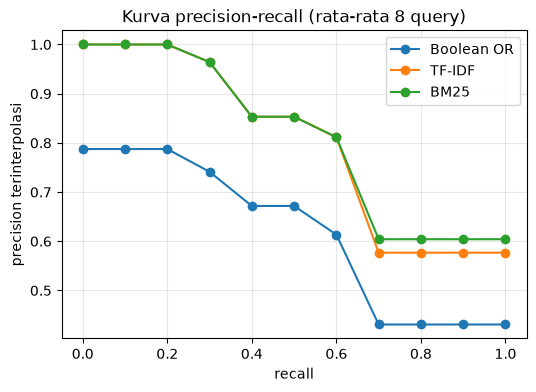

In [11]:
def interpolated_pr(ranking, relevan):
    titik, hits = [], 0
    for i, d in enumerate(ranking, start=1):
        if d in relevan:
            hits += 1
        titik.append((hits / len(relevan), hits / i))
    return [max([p for r, p in titik if r >= level], default=0.0) for level in [i / 10 for i in range(11)]]

level = [i / 10 for i in range(11)]
plt.figure(figsize=(6, 4))
for nama, run in [("Boolean OR", run_bool), ("TF-IDF", run_tfidf), ("BM25", run_bm25)]:
    kurva = [sum(v) / len(v) for v in zip(*(interpolated_pr(run[q], set(qrels[q])) for q in queries))]
    plt.plot(level, kurva, marker="o", label=nama)
plt.xlabel("recall"); plt.ylabel("precision terinterpolasi")
plt.title("Kurva precision-recall (rata-rata 8 query)")
plt.legend(); plt.grid(alpha=.3); plt.show()

## Tugas Step 6
1. Tambahkan 4 query baru beserta relevance judgment-nya ke `qrels.csv` (diskusikan penilaian dengan rekan satu kelompok). Laporkan tingkat kesepakatan penilai.
2. Hitung **R-Precision** dan **Mean Reciprocal Rank (MRR)** untuk ketiga model.
3. Query mana yang kinerjanya paling buruk pada BM25? Lakukan analisis kegagalan (*failure analysis*): apakah penyebabnya preprocessing, ketidakcocokan kosakata (*vocabulary mismatch*), atau penilaian relevansi?
4. Gunakan fungsi evaluasi untuk menyelesaikan grid search $k_1$ dan $b$ pada Tugas Step 5.

### Jawaban Tugas 1

Empat query baru ditambahkan ke `queries.csv` dan `qrels.csv` (skala 2 = sangat relevan, 1 = relevan sebagian, tidak tercantum = 0).

| Query | Teks query | Dokumen relevan | Alasan |
|---|---|---|---|
| Q9 | olahraga mencegah penyakit jantung dan diabetes | D03 (2), D04 (2) | D03 membahas olahraga dan penyakit jantung; D04 membahas olahraga untuk mencegah diabetes |
| Q10 | kecerdasan buatan dan pembelajaran mesin | D14 (2), D17 (1), D18 (1) | D14 membahas kecerdasan buatan dan pembelajaran mesin; D17 (NLP) dan D18 (big data) hanya berkaitan sebagian |
| Q11 | modal usaha dan pembayaran digital untuk pedagang kecil | D22 (2), D21 (2), D19 (1) | D22 membahas modal usaha (KUR); D21 membahas pembayaran digital (QRIS); D19 membahas digitalisasi UMKM |
| Q12 | mengendalikan hama pada tanaman padi | D11 (2), D07 (2) | D11 membahas pengendalian hama; D07 membahas hama pada tanaman padi |

**Tingkat kesepakatan penilai.** Penilaian dilakukan oleh dua penilai secara terpisah: penilai 1 (penulis) dan penilai 2. Kesepakatan dihitung pada 4 query × 30 dokumen = 120 pasangan query–dokumen (dokumen yang tidak dicantumkan dihitung 0).

| Ukuran | Nilai |
|---|---|
| Agreement (proporsi sama) | 0,983 (118 dari 120) |
| Cohen's kappa | 0,888 |
| Kappa berbobot linear | 0,933 |

Menurut skala Landis & Koch, κ di atas 0,80 berarti kesepakatan hampir sempurna. Dua pasangan berbeda:
- **Q10–D18 (big data): penilai 1 = 1, penilai 2 = 0.** Dokumen hanya membahas analisis data dan tidak menyebut kecerdasan buatan maupun pembelajaran mesin, sehingga penilai 2 menganggapnya tidak relevan.
- **Q12–D07 (budidaya padi): penilai 1 = 2, penilai 2 = 1.** D07 hanya menyebut hama wereng sebagai ancaman dan tidak membahas cara mengendalikannya, jadi penilai 2 menilainya relevan sebagian. Hanya D11 yang membahas pengendalian.

Perbedaan hanya satu tingkat (bukan relevan vs tidak relevan secara ekstrem pada Q12) sehingga kappa berbobot lebih tinggi dari kappa biasa. Judgment final di `qrels.csv` memakai penilaian penulis; perbedaan di atas tidak mengubah kesimpulan evaluasi secara berarti.

In [12]:
from collections import Counter
from stki_utils import load_corpus

baru = ["Q9", "Q10", "Q11", "Q12"]
semua_doc = list(load_corpus().doc_id)

def cohen_kappa(a, b, labels=(0, 1, 2), weighted=False):
    n = len(a); L = list(labels)
    obs, ca, cb = Counter(zip(a, b)), Counter(a), Counter(b)
    w = (lambda i, j: abs(i - j) / (max(L) - min(L))) if weighted else (lambda i, j: 0 if i == j else 1)
    do = sum(w(i, j) * obs[(i, j)] / n for i in L for j in L)
    de = sum(w(i, j) * ca[i] * cb[j] / n**2 for i in L for j in L)
    return 1 - do / de if de else 1.0

# penilaian rekan: file qrels_penilai2.csv (format sama seperti qrels.csv)
p2 = pd.read_csv("../Data/qrels_penilai2.csv")
q2 = {}
for q, d, r in p2.itertuples(index=False):
    q2.setdefault(q, {})[d] = r

A = [qrels[q].get(d, 0) for q in baru for d in semua_doc]        # penilai 1 (Anda)
B = [q2.get(q, {}).get(d, 0) for q in baru for d in semua_doc]   # penilai 2 (rekan)
print(len(A), "pasangan | agreement =", sum(x == y for x, y in zip(A, B)) / len(A))
print("kappa =", round(cohen_kappa(A, B), 4),
      "| kappa berbobot =", round(cohen_kappa(A, B, weighted=True), 4))

120 pasangan | agreement = 0.9833333333333333
kappa = 0.8878 | kappa berbobot = 0.9329


## Tugas 2 — R-Precision dan Mean Reciprocal Rank (MRR)

- **R-Precision**: precision pada posisi ke-R, dengan R = jumlah dokumen relevan untuk query tersebut.
- **Reciprocal Rank (RR)**: 1 / posisi dokumen relevan pertama (0 jika tidak ada). **MRR** = rata-rata RR seluruh query.

In [13]:
import numpy as np

def r_precision(ranked, relevan):
    R = len(relevan)
    return sum(1 for d in ranked[:R] if d in relevan) / R if R else 0.0

def reciprocal_rank(ranked, relevan):
    for i, d in enumerate(ranked, start=1):
        if d in relevan:
            return 1 / i
    return 0.0

runs = {"Boolean OR": run_bool, "TF-IDF (VSM)": run_tfidf, "BM25": run_bm25}

# nilai per query
per_query = pd.DataFrame({
    (nama, m): [f(run[q], set(qrels[q])) for q in queries]
    for nama, run in runs.items()
    for m, f in [("R-Prec", r_precision), ("RR", reciprocal_rank)]
}, index=list(queries))
display(per_query.round(4))

# ringkasan
ringkas_2 = pd.DataFrame({
    nama: {"R-Precision": np.mean([r_precision(run[q], set(qrels[q])) for q in queries]),
           "MRR": np.mean([reciprocal_rank(run[q], set(qrels[q])) for q in queries])}
    for nama, run in runs.items()
}).T.round(4)
ringkas_2

Boolean OR         TF-IDF (VSM)         BM25     
        R-Prec      RR       R-Prec   RR  R-Prec   RR
Q1      0.5000  1.0000       0.5000  1.0  0.5000  1.0
Q2      0.7500  0.5000       0.2500  1.0  0.2500  1.0
Q3      0.6667  1.0000       0.6667  1.0  0.6667  1.0
Q4      0.6667  1.0000       0.6667  1.0  0.6667  1.0
Q5      1.0000  1.0000       0.6667  1.0  1.0000  1.0
Q6      0.3333  1.0000       0.6667  1.0  0.6667  1.0
Q7      0.2500  1.0000       1.0000  1.0  1.0000  1.0
Q8      0.3333  0.3333       0.6667  1.0  0.6667  1.0
Q9      0.0000  0.3333       1.0000  1.0  1.0000  1.0
Q10     0.0000  0.2500       0.3333  1.0  0.3333  1.0
Q11     0.6667  0.5000       1.0000  1.0  1.0000  1.0
Q12     0.5000  0.5000       1.0000  1.0  1.0000  1.0

,R-Precision,MRR
Boolean OR,0.4722,0.7014
TF-IDF (VSM),0.7014,1.0000
BM25,0.7292,1.0000


## Tugas 3 — Query terburuk pada BM25 dan analisis kegagalan

In [14]:
eval_bm25 = evaluate(run_bm25, qrels, k=5).drop("Rata-rata")
print(eval_bm25.sort_values("AP").head(3))

terburuk = eval_bm25["AP"].idxmin()
print("\nQuery terburuk:", terburuk, "-", queries[terburuk])
print("Token query   :", preprocess(queries[terburuk]))
print("Relevan (qrels):", qrels[terburuk])

for rank, (d, s) in enumerate(bm25.search(preprocess(queries[terburuk]), k=10), 1):
    print(rank, d, round(s, 3), "REL =", qrels[terburuk].get(d, 0))

print("\nTerm query yang cocok di dokumen relevan:")
for d in qrels[terburuk]:
    print(d, sorted(set(preprocess(queries[terburuk])) & set(docs[d])))

          P@5     R@5    F1@5      AP  nDCG@5
query_id                                     
Q10       0.2  0.3333  0.2500  0.4167  0.6388
Q4        0.4  0.6667  0.5000  0.5556  0.7975
Q2        0.4  0.5000  0.4444  0.6179  0.5693

Query terburuk: Q10 - kecerdasan buatan dan pembelajaran mesin
Token query   : ['cerdas', 'buat', 'ajar', 'mesin']
Relevan (qrels): {'D14': 2, 'D17': 1, 'D18': 1}
1 D14 11.57 REL = 2
2 D08 4.188 REL = 0
3 D27 3.85 REL = 0
4 D13 3.434 REL = 0
5 D10 3.074 REL = 0
6 D25 2.621 REL = 0
7 D26 2.33 REL = 0
8 D17 2.086 REL = 1
9 D30 1.607 REL = 0

Term query yang cocok di dokumen relevan:
D14 ['ajar', 'buat', 'cerdas', 'mesin']
D17 ['ajar']
D18 []


## Tugas 4 — Grid search k₁ dan b (Tugas Step 5)
Rentang: k₁ ∈ {0,5; 1,0; 1,2; 1,5; 2,0} dan b ∈ {0; 0,25; 0,5; 0,75; 1,0}. Kriteria: MAP terbaik (nDCG@5 sebagai pemecah seri), memakai fungsi evaluate dari Step 6.

In [15]:
k1_list = [0.5, 1.0, 1.2, 1.5, 2.0]
b_list = [0, 0.25, 0.5, 0.75, 1.0]

hasil = []
for k1 in k1_list:
    for b in b_list:
        m = BM25Model(docs, k1=k1, b=b)
        run = {q: [d for d, _ in m.search(preprocess(t), k=10)] for q, t in queries.items()}
        ev = evaluate(run, qrels, k=5).loc["Rata-rata"]
        hasil.append({"k1": k1, "b": b, "MAP": ev["AP"], "P@5": ev["P@5"], "nDCG@5": ev["nDCG@5"]})

grid = pd.DataFrame(hasil)
display(grid.pivot(index="k1", columns="b", values="MAP").round(4))

urut = grid.sort_values(["MAP", "nDCG@5"], ascending=False)
display(urut.head(5).round(4))
terbaik = urut.iloc[0]
print("Terbaik:", terbaik.to_dict())
print("Default (k1=1.5, b=0.75): MAP =",
      round(grid[(grid.k1 == 1.5) & (grid.b == 0.75)].MAP.iloc[0], 4))

b,0.00,0.25,0.50,0.75,1.00
k1,,,,,
0.5,0.8002,0.7969,0.7969,0.7969,0.7969
1.0,0.8051,0.8018,0.8018,0.8018,0.8018
1.2,0.8051,0.8018,0.8018,0.8018,0.8018
1.5,0.8051,0.8018,0.8018,0.8018,0.8018
2.0,0.8051,0.8018,0.8018,0.8018,0.8018


,k1,b,MAP,P@5,nDCG@5
5,1.0,0.00,0.8051,0.4500,0.8731
10,1.2,0.00,0.8051,0.4500,0.8731
15,1.5,0.00,0.8051,0.4500,0.8731
20,2.0,0.00,0.8051,0.4500,0.8731
6,1.0,0.25,0.8018,0.4667,0.8811


Terbaik: {'k1': 1.0, 'b': 0.0, 'MAP': 0.8051, 'P@5': 0.45, 'nDCG@5': 0.8731}
Default (k1=1.5, b=0.75): MAP = 0.8018
